# Exploratory Data Analysis of the Ames Housing Dataset

## 1. Introduction

### Project Objective
The objective of this project is to conduct a comprehensive **Exploratory Data Analysis (EDA)**—without any machine learning modeling—on the Ames Housing Dataset (`train.csv`) to understand which factors drive residential house sale prices and to follow a complete, reproducible EDA workflow.

### Dataset Description
- **Source**: Kaggle *House Prices: Advanced Regression Techniques* (`train.csv`, accompanied by `data_description.txt`)
- **Size**: 1,460 residential property sales (rows) and 81 variables (columns: `Id`, 79 explanatory features, and the target variable `SalePrice`)
- **Tools**: Python, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`

### Guiding Questions (Formulated Before Inspecting the Data)
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they data errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

## 2. Data Loading (Step 1: Setup and First Look)

### What We Are About to Do
We will import the core Python data science and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`), configure a clean default plotting theme and figure size, load `train.csv` into a DataFrame `df`, and inspect its shape, first five rows, column data types, and missing value counts/percentages.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure consistent plotting style and default figure size
sns.set_theme(style="whitegrid", context="notebook", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

df = pd.read_csv("train.csv")

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: 1460 rows x 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### What We Learned
- The training dataset contains **1,460 rows** and **81 columns**, matching the expected Ames Housing schema (`Id`, 79 features, and `SalePrice`).
- Visual inspection of the first five rows immediately reveals several `NaN` entries in columns like `Alley`, `FireplaceQu`, `PoolQC`, `Fence`, and `MiscFeature`, which `data_description.txt` defines as `"NA"` meaning *feature absent* rather than unknown.

### What We Are About to Do
Next, we will inspect `df.info()` to check column names, data types, and non-null counts across all 81 columns, and then compute and sort every column with missing values (`missing > 0`) along with its missing percentage.

In [2]:
df.info()

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": (missing / len(df) * 100).round(2),
    "Dtype": df.dtypes[missing.index].astype(str)
})

print(f"\nNumber of columns with missing values: {len(missing_df)} out of {df.shape[1]}")
display(missing_df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Missing Count,Missing %,Dtype
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


### Deliverable — Step 1 First Impressions
- **Rows & Columns**: **1,460 rows** and **81 columns** (35 `int64`, 3 `float64`, and 43 `object` columns).
- **Columns with Missing Values**: **19 columns** contain missing values.
- **First Impressions**:
  - The top missing columns—`PoolQC` (99.52%), `MiscFeature` (96.30%), `Alley` (93.77%), `Fence` (80.75%), `MasVnrType` (59.73%), and `FireplaceQu` (47.26%)—primarily represent optional property amenities where `NA` (or literal `"None"` in `MasVnrType`, which `pandas.read_csv` parses as `NaN` by default) means the feature does not exist.
  - Basement (`Bsmt*`, 37–38 missing) and garage (`Garage*`, 81 missing) columns appear in synchronized blocks, suggesting homes without basements or garages.
  - `LotFrontage` (259 missing, 17.74%) and `Electrical` (1 missing, 0.07%) look like genuine missing measurements.

## 3. Data Understanding (Steps 2 and 3)

### What We Are About to Do (Step 2: Classify Variables)
We will split the columns into `numeric_cols` and `categorical_cols`, convert the ordinal quality columns `ExterQual` and `KitchenQual` into ordered `pd.Categorical` types (`Po < Fa < TA < Gd < Ex`), and build a comprehensive summary table displaying each column's name, analytical variable type (`Numerical (continuous)`, `Numerical (discrete)`, `Categorical (nominal)`, or `Categorical (ordinal)`), number of unique values, and example values.

In [3]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

# Analytical classification helper following Section 4 Variable Reference
discrete_num_cols = {
    "Id", "MSSubClass", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd",
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
    "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageYrBlt", "GarageCars",
    "MoSold", "YrSold"
}
ordinal_cat_cols = {
    "LotShape", "Utilities", "LandSlope", "ExterQual", "ExterCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "HeatingQC", "Electrical", "KitchenQual", "Functional", "FireplaceQu",
    "GarageFinish", "GarageQual", "GarageCond", "PavedDrive", "PoolQC", "Fence"
}

def classify_var(col):
    if col in {"OverallQual", "OverallCond"}:
        return "Numerical (discrete / ordinal scale)"
    if col in numeric_cols:
        return "Numerical (discrete)" if col in discrete_num_cols else "Numerical (continuous)"
    if col in ordinal_cat_cols:
        return "Categorical (ordinal)"
    return "Categorical (nominal)"

summary_rows = []
for col in df.columns:
    non_null_vals = df[col].dropna().unique()
    examples = ", ".join(map(str, non_null_vals[:4]))
    summary_rows.append({
        "Column Name": col,
        "Pandas Dtype": str(df[col].dtype),
        "Variable Type": classify_var(col),
        "Unique Values": df[col].nunique(dropna=True),
        "Example Values": examples
    })

var_summary = pd.DataFrame(summary_rows)
print(f"Numeric columns: {len(numeric_cols)} | Object/Category columns: {df.shape[1] - len(numeric_cols)}")
print("Variable Type Breakdown:")
display(var_summary["Variable Type"].value_counts().to_frame("Column Count"))
display(var_summary)

Numeric columns: 38 | Object/Category columns: 43
Variable Type Breakdown:


,Column Count
Variable Type,
Categorical (nominal),22
Categorical (ordinal),21
Numerical (continuous),20
Numerical (discrete),16
Numerical (discrete / ordinal scale),2


,Column Name,Pandas Dtype,Variable Type,Unique Values,Example Values
0,Id,int64,Numerical (discrete),1460,"1, 2, 3, 4"
1,MSSubClass,int64,Numerical (discrete),15,"60, 20, 70, 50"
2,MSZoning,object,Categorical (nominal),5,"RL, RM, C (all), FV"
3,LotFrontage,float64,Numerical (continuous),110,"65.0, 80.0, 68.0, 60.0"
4,LotArea,int64,Numerical (continuous),1073,"8450, 9600, 11250, 9550"
...,...,...,...,...,...
76,MoSold,int64,Numerical (discrete),12,"2, 5, 9, 12"
77,YrSold,int64,Numerical (discrete),5,"2008, 2007, 2006, 2009"
78,SaleType,object,Categorical (nominal),9,"WD, New, COD, ConLD"
79,SaleCondition,object,Categorical (nominal),6,"Normal, Abnorml, Partial, AdjLand"


### What We Learned (Step 2)
- The dataset contains **38 numeric columns** and **43 non-numeric columns** (`object` / ordered `category`), with `ExterQual` and `KitchenQual` explicitly encoded as ordered categorical variables (`Po < Fa < TA < Gd < Ex`).
- **Important nuance**: `OverallQual` (1–10) and `OverallCond` (1–10) are stored as `int64` numbers, **but conceptually they are ordinal variables** representing ordered quality/condition tiers rather than continuous physical measurements. Similarly, `MSSubClass` is stored as an integer code but actually represents nominal dwelling categories.

### What We Are About to Do (Step 3: Descriptive Statistics)
We will generate `df[numeric_cols].describe()` for an overview of all numeric features, then compute detailed centre and spread metrics (`mean`, `median`, `mode`, `std`, `var`, `range`, `iqr`, `skewness`, `kurtosis`) for `SalePrice`, `GrLivArea`, and `LotArea`, and inspect frequency counts and modes for `Neighborhood` and `HouseStyle`.

In [4]:
display(df[numeric_cols].describe().T.round(2))

key_num = ["SalePrice", "GrLivArea", "LotArea"]
stats_rows = []
for col in key_num:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode().iloc[0]
    std_val = s.std()
    var_val = s.var()
    val_range = s.max() - s.min()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = s.skew()
    kurt_val = s.kurt()  # Excess kurtosis (Fisher)
    skew_note = "right skewed" if mean_val > median_val else ("left skewed" if mean_val < median_val else "symmetric")
    stats_rows.append({
        "Feature": col,
        "Mean": round(mean_val, 2),
        "Median": round(median_val, 2),
        "Mode": round(mode_val, 2),
        "Std": round(std_val, 2),
        "Variance": round(var_val, 2),
        "Range": round(val_range, 2),
        "IQR": round(iqr_val, 2),
        "Skewness": round(skew_val, 4),
        "Kurtosis": round(kurt_val, 4),
        "Shape Note": skew_note
    })

display(pd.DataFrame(stats_rows))

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {col} Value Counts (Mode: {df[col].mode().iloc[0]}) ---")
    display(df[col].value_counts().to_frame("Count"))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


,Feature,Mean,Median,Mode,Std,Variance,Range,IQR,Skewness,Kurtosis,Shape Note
0,SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.8829,6.5363,right skewed
1,GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.3666,4.8951,right skewed
2,LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.2077,203.2433,right skewed



--- Neighborhood Value Counts (Mode: NAmes) ---


,Count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



--- HouseStyle Value Counts (Mode: 1Story) ---


,Count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


### What We Learned (Step 3) & Interpretation Prompt
- **Centre & Spread**:
  - `SalePrice`: Mean = **\$180,921.20**, Median = **\$163,000.00**, Mode = **\$140,000.00**, Std = **\$79,442.50**, IQR = **\$84,025.00**, Range = **\$720,100** (\$34,900 to \$755,000), Skewness = **1.8829**, Excess Kurtosis = **6.5363** (*right skewed*).
  - `GrLivArea`: Mean = **1,515.46 sq ft**, Median = **1,464.00 sq ft**, Mode = **864 sq ft**, IQR = **647.25 sq ft**, Skewness = **1.3666** (*right skewed*).
  - `LotArea`: Mean = **10,516.83 sq ft**, Median = **9,478.50 sq ft**, Std = **9,981.26 sq ft**, Skewness = **12.2077**, Kurtosis = **203.2433** (*heavily right skewed* due to a few massive lots up to 215,245 sq ft).
- **Categorical Frequencies**:
  - `Neighborhood` has 25 distinct neighborhoods; the mode is **NAmes** (North Ames, 225 sales), followed by **CollgCr** (150) and **OldTown** (113).
  - `HouseStyle` has 8 styles; the mode is **1Story** (726 sales, nearly half the dataset), followed by **2Story** (445) and **1.5Fin** (154).
- **Interpretation Prompt — What does the gap between mean and median of `SalePrice` tell us?**
  - The mean (\$180,921.20) exceeds the median (\$163,000.00) by **\$17,921.20** (~11% higher). Because the mean is pulled toward extreme values while the median resists them, this positive gap confirms a **pronounced right skew**: most homes sell in a moderate band around \$130k–\$214k, while a smaller tail of luxury properties (up to \$755,000) stretches the upper tail and inflates the average.

## 4. Data Cleaning & Quality Checks (Step 9)

Following the suggested notebook structure, we run Step 9 early so that any duplicate rows, inconsistent labels, impossible dates, or misleading `"NA"` values are documented and cleanly resolved before visualization and correlation analysis.

### What We Are About to Do
We will check for exact duplicate rows (both with and without `Id`), scan all categorical columns for casing inconsistencies, extra whitespace, or similar spellings, audit impossible values (negative areas or construction/remodel dates after `YrSold`), and carefully clean missing values while preserving the domain meaning of `"NA"` (*feature absent*).

In [5]:
# 1. Duplicate check
dup_count = df.duplicated().sum()
dup_no_id = df.drop(columns=["Id"]).duplicated().sum()
print(f"Exact duplicate rows: {dup_count}")
print(f"Duplicate rows excluding 'Id': {dup_no_id}")
if dup_count > 0:
    df = df.drop_duplicates().copy()
    print(f"New shape after removing duplicates: {df.shape}")

# 2. Categorical label consistency check (casing, whitespace, spelling variants)
cat_check_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
inconsistencies = []
for col in cat_check_cols:
    vals = [str(v) for v in df[col].dropna().unique()]
    has_ws = any(v != v.strip() for v in vals)
    lower_set = {v.strip().lower() for v in vals}
    if has_ws or len(lower_set) != len(vals):
        inconsistencies.append((col, vals))

print(f"Categorical columns with casing/whitespace inconsistencies: {len(inconsistencies)}")
for col, vals in inconsistencies:
    print(f"  - {col}: {vals}")

# 3. Impossible / anomalous value checks
print("\nImpossible value checks:")
print(f"  YearBuilt > YrSold: {(df['YearBuilt'] > df['YrSold']).sum()}")
print(f"  YearRemodAdd > YrSold: {(df['YearRemodAdd'] > df['YrSold']).sum()}")
print(f"  GarageYrBlt > YrSold: {(df['GarageYrBlt'] > df['YrSold']).sum()}")
neg_cols = [c for c in numeric_cols if (df[c].dropna() < 0).any()]
print(f"  Numeric columns with negative values: {neg_cols}")

if (df["YearRemodAdd"] > df["YrSold"]).sum() > 0:
    print("\nRow with YearRemodAdd > YrSold:")
    display(df[df["YearRemodAdd"] > df["YrSold"]][["Id", "YearBuilt", "YearRemodAdd", "YrSold", "GrLivArea", "SalePrice", "SaleCondition"]])

Exact duplicate rows: 0
Duplicate rows excluding 'Id': 0
Categorical columns with casing/whitespace inconsistencies: 0

Impossible value checks:
  YearBuilt > YrSold: 0
  YearRemodAdd > YrSold: 1
  GarageYrBlt > YrSold: 0
  Numeric columns with negative values: []

Row with YearRemodAdd > YrSold:


,Id,YearBuilt,YearRemodAdd,YrSold,GrLivArea,SalePrice,SaleCondition
523,524,2007,2008,2007,4676,184750,Partial


### What We Learned
- **Duplicates**: There are **0 duplicate rows** (both with and without `Id`).
- **Category Labels**: All 43 categorical/ordinal columns have consistent casing and no trailing/leading whitespace (`0` inconsistencies found).
- **Impossible / Anomalous Dates**: There are **0 negative numeric values**, **0** rows with `YearBuilt > YrSold`, and **0** rows with `GarageYrBlt > YrSold`. However, **1 row (`Id=524`)** has `YearRemodAdd = 2008` while `YrSold = 2007` (`SaleCondition = Partial`), indicating a post-sale assessment/remodel update on an incomplete new home—notably, this is also one of the extreme living-area outliers we will inspect later in Step 8.

### What We Are About to Do
Now we will apply documented missing-value cleaning to `df`:
1. **Categorical "Feature Absent" Columns** (`PoolQC`, `Alley`, `Fence`, `FireplaceQu`, `GarageType`, plus `MiscFeature`, `GarageFinish`, `GarageQual`, `GarageCond`, `BsmtQual`, `BsmtCond`, `BsmtExposure` where basement is absent, `BsmtFinType1`, `BsmtFinType2` where basement is absent, and `MasVnrType`): fill `NaN` with `"None"` since `data_description.txt` specifies `NA` means *no such feature* (and `MasVnrType` literal `"None"` values were parsed as `NaN` by pandas).
2. **True Missing Categorical Values**: `Electrical` (1 missing, `Id=1380`), `BsmtExposure` (`Id=949`, has basement), and `BsmtFinType2` (`Id=333`, has `BsmtFinSF2=479`) will be filled with each column's mode.
3. **Numeric Missing Values**:
   - `LotFrontage` (259 missing): fill with the **median `LotFrontage` grouped by `Neighborhood`** (falling back to overall median if needed), because lot frontage depends strongly on neighborhood lot layout.
   - `MasVnrArea` (8 missing, all with no masonry veneer): fill with `0.0`.
   - `GarageYrBlt` (81 missing, houses without a garage): fill with the overall median of `GarageYrBlt` (so year-scale correlations are not distorted by inserting `0`), while `GarageType == "None"` explicitly preserves the *no garage* signal.
4. Finally, verify that remaining missing values equal **0** across the entire DataFrame.

In [6]:
# 1. Core 'NA means feature absent' columns from Step 9 + related basement/garage/misc/masonry columns
feature_absent_cols = [
    "PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType",
    "MiscFeature", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtFinType1", "MasVnrType"
]
for col in feature_absent_cols:
    df[col] = df[col].fillna("None")

# BsmtExposure & BsmtFinType2: 37 rows truly have no basement ('None'); 1 row each is genuinely missing
no_bsmt_mask = df["BsmtQual"] == "None"
df.loc[no_bsmt_mask, ["BsmtExposure", "BsmtFinType2"]] = "None"

for col in ["BsmtExposure", "BsmtFinType2", "Electrical"]:
    mode_val = df[col].mode().iloc[0]
    df[col] = df[col].fillna(mode_val)

# 2. Numeric missing values
df["LotFrontage"] = df["LotFrontage"].fillna(
    df.groupby("Neighborhood")["LotFrontage"].transform("median")
)
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

df["MasVnrArea"] = df["MasVnrArea"].fillna(0.0)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["GarageYrBlt"].median())

# 3. Verify zero missing values remain
remaining_missing = int(df.isnull().sum().sum())
print(f"Total remaining missing values in df: {remaining_missing}")
assert remaining_missing == 0, "Expected zero missing values after cleaning!"

Total remaining missing values in df: 0


### What We Learned
- All **19 columns** with missing values are now resolved with **0 remaining missing values** (`df.isnull().sum().sum() == 0`) without dropping a single property record.
- Critically, **most missing entries were not missing data at all**: `PoolQC` (1,453), `MiscFeature` (1,406), `Alley` (1,369), `Fence` (1,179), `FireplaceQu` (690), `Garage*` (81), and `Bsmt*` (37) reflect the absence of a pool, alley, fence, fireplace, garage, or basement. Dropping rows with `NA` would have destroyed almost the entire dataset!

## 5. Univariate Analysis (Step 4: Distributions)

### What We Are About to Do
We will visualize the distribution of `SalePrice` using a 1×3 figure (using `sns.histplot(..., kde=True)` rather than the deprecated `distplot`, alongside a boxplot and a histogram of `log(SalePrice)`), comparing skewness before and after the log transformation.

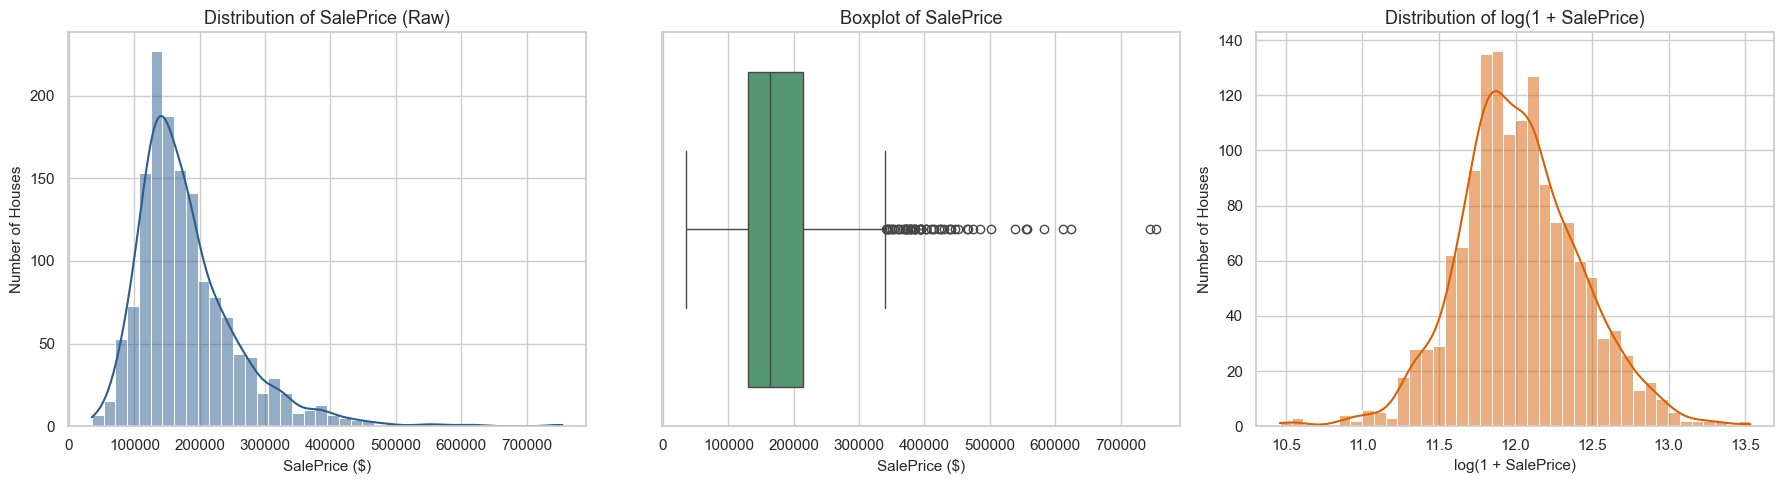

Skewness before log transform: 1.8829
Skewness after log1p transform: 0.1213


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Axis 1: Histogram + KDE of SalePrice
sns.histplot(df["SalePrice"], kde=True, bins=40, color="#2b5c8f", ax=axes[0])
axes[0].set_title("Distribution of SalePrice (Raw)")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Number of Houses")

# Axis 2: Boxplot of SalePrice
sns.boxplot(x=df["SalePrice"], color="#4c9f70", ax=axes[1])
axes[1].set_title("Boxplot of SalePrice")
axes[1].set_xlabel("SalePrice ($)")

# Axis 3: Histogram + KDE of log(SalePrice)
log_price = np.log1p(df["SalePrice"])
sns.histplot(log_price, kde=True, bins=40, color="#d95f02", ax=axes[2])
axes[2].set_title("Distribution of log(1 + SalePrice)")
axes[2].set_xlabel("log(1 + SalePrice)")
axes[2].set_ylabel("Number of Houses")

plt.tight_layout()
plt.show()

print(f"Skewness before log transform: {df['SalePrice'].skew():.4f}")
print(f"Skewness after log1p transform: {log_price.skew():.4f}")

### What We Learned
- Raw `SalePrice` is **strongly right-skewed** (skewness = **1.8829**) with a long upper tail of high-value properties visible in both the KDE curve and the numerous high-end boxplot points above ~\$340k.
- Applying a log transform (`log1p`) compresses the upper tail and reduces skewness from **1.8829** down to **0.1213**, yielding a nearly symmetric, approximately normal bell-shaped distribution.

### What We Are About to Do
Next, we will explore how `SalePrice` varies across `OverallQual` and `Neighborhood` (sorted by median sale price with x-axis labels rotated 90 degrees), and plot frequency countplots for `OverallQual` and `HouseStyle`.

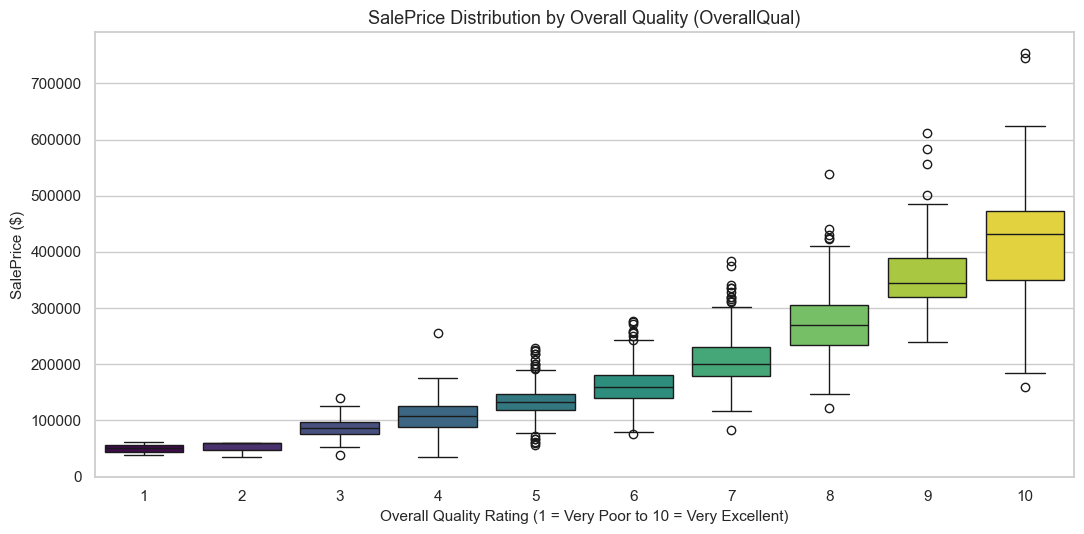

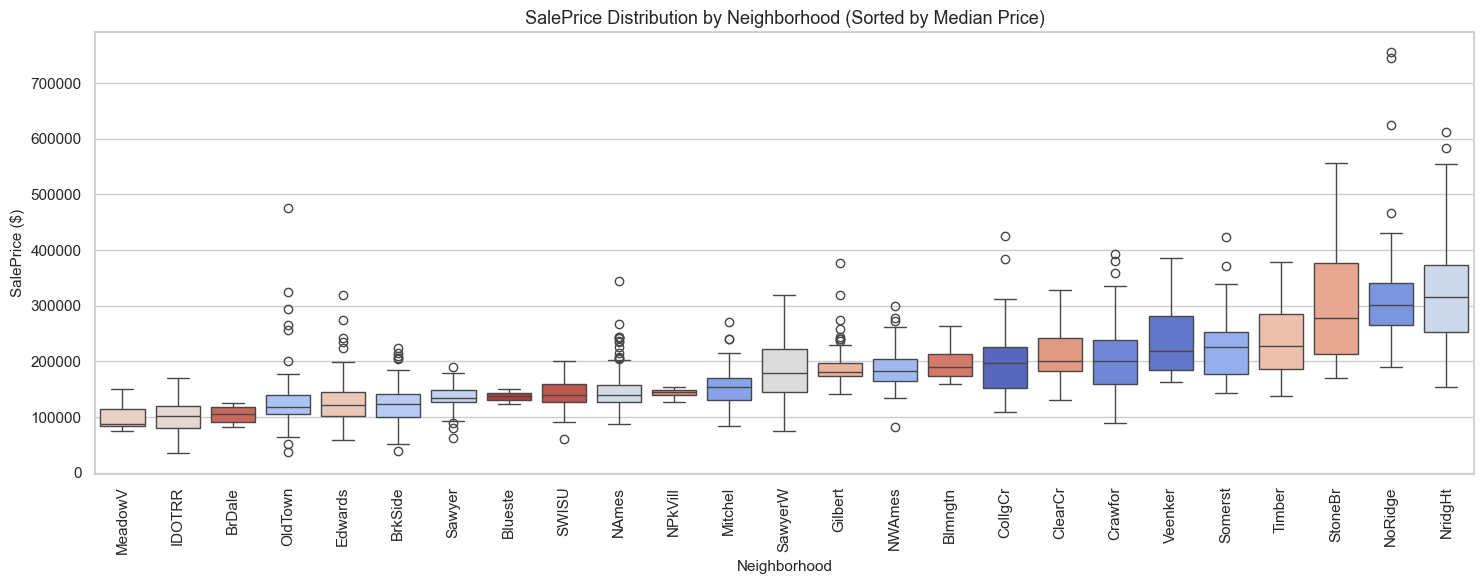

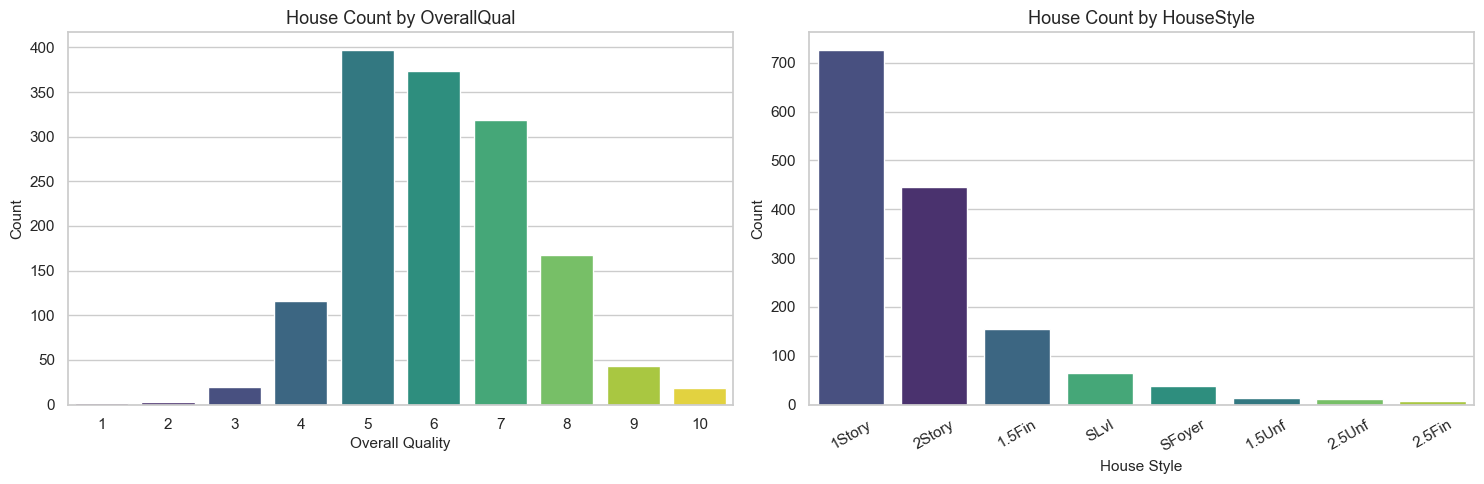

In [8]:
# Boxplot of SalePrice grouped by OverallQual
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="viridis", hue="OverallQual", legend=False, ax=ax)
ax.set_title("SalePrice Distribution by Overall Quality (OverallQual)")
ax.set_xlabel("Overall Quality Rating (1 = Very Poor to 10 = Very Excellent)")
ax.set_ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

# Boxplot of SalePrice grouped by Neighborhood (sorted by median price)
neigh_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neigh_order, palette="coolwarm", hue="Neighborhood", legend=False, ax=ax)
ax.set_title("SalePrice Distribution by Neighborhood (Sorted by Median Price)")
ax.set_xlabel("Neighborhood")
ax.set_ylabel("SalePrice ($)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

# Countplots of OverallQual and HouseStyle
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="OverallQual", palette="viridis", hue="OverallQual", legend=False, ax=axes[0])
axes[0].set_title("House Count by OverallQual")
axes[0].set_xlabel("Overall Quality")
axes[0].set_ylabel("Count")

style_order = df["HouseStyle"].value_counts().index
sns.countplot(data=df, x="HouseStyle", order=style_order, palette="viridis", hue="HouseStyle", legend=False, ax=axes[1])
axes[1].set_title("House Count by HouseStyle")
axes[1].set_xlabel("House Style")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### What We Learned
- **Quality drives price monotonically**: Median `SalePrice` rises smoothly at every single tier of `OverallQual`, from **\$50,150** (rating 1) and **\$133,000** (rating 5) up to **\$345,000** (rating 9) and **\$432,390** (rating 10). Price spread (IQR and whiskers) also widens substantially at the top tiers (`OverallQual` 8–10).
- **Strong neighborhood stratification**: Median prices span more than 3.5× across neighborhoods—from **MeadowV (\$88,000)**, **IDOTRR (\$103,000)**, and **BrDale (\$106,000)** at the affordable end up to **StoneBr (\$278,000)**, **NoRidge (\$301,500)**, and **NridgHt (\$315,000)** at the luxury end.
- **Inventory concentration**: Most homes fall in `OverallQual` **5–7** (1,090 of 1,460 homes, 74.7%), and **1Story** (726) and **2Story** (445) styles together make up 80.2% of all sales.

## 6. Bivariate and Multivariate Analysis (Steps 5, 6, and 7)

### What We Are About to Do (Step 5: Correlation and Covariance)
We will compute the covariance matrix and Pearson correlation matrix across numeric columns, rank the top 10 features most strongly correlated with `SalePrice` (by absolute Pearson `r`), compare covariance vs. correlation for the top 3 features, and compute Spearman rank correlations for key ordinal quality features (`OverallQual`, `OverallCond`, `ExterQual`, `KitchenQual`).

In [9]:
cov_matrix = df[numeric_cols].cov()
corr_matrix = df[numeric_cols].corr(method="pearson")

top_corr_abs = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top10_features = top_corr_abs.head(10).index.tolist()

top10_table = pd.DataFrame({
    "Feature": top10_features,
    "Pearson r": [round(corr_matrix.loc[c, "SalePrice"], 4) for c in top10_features],
    "Abs Pearson r": [round(top_corr_abs[c], 4) for c in top10_features],
    "Covariance with SalePrice": [round(cov_matrix.loc[c, "SalePrice"], 2) for c in top10_features]
})
print("Top 10 Numeric Features Correlated with SalePrice:")
display(top10_table)

print("\nTop 3 Features — Covariance vs. Correlation:")
for col in top10_features[:3]:
    print(f"  {col:12s} | Covariance = {cov_matrix.loc[col, 'SalePrice']:14,.2f} | Pearson r = {corr_matrix.loc[col, 'SalePrice']:.4f}")

# Optional: Spearman correlation for ordinal columns
ordinal_numeric = pd.DataFrame({
    "OverallQual": df["OverallQual"],
    "OverallCond": df["OverallCond"],
    "ExterQual": df["ExterQual"].cat.codes + 1,
    "KitchenQual": df["KitchenQual"].cat.codes + 1,
    "SalePrice": df["SalePrice"]
})
print("\nSpearman Rank Correlation of Ordinal Features with SalePrice:")
display(ordinal_numeric.corr(method="spearman")[["SalePrice"]].sort_values("SalePrice", ascending=False).round(4))

print(f"\nCollinear pair check — GarageArea vs GarageCars Pearson r: {corr_matrix.loc['GarageArea', 'GarageCars']:.4f}")
print(f"Collinear pair check — TotalBsmtSF vs 1stFlrSF Pearson r: {corr_matrix.loc['TotalBsmtSF', '1stFlrSF']:.4f}")
print(f"Collinear pair check — GrLivArea vs TotRmsAbvGrd Pearson r: {corr_matrix.loc['GrLivArea', 'TotRmsAbvGrd']:.4f}")

Top 10 Numeric Features Correlated with SalePrice:


,Feature,Pearson r,Abs Pearson r,Covariance with SalePrice
0,OverallQual,0.7910,0.7910,86904.13
1,GrLivArea,0.7086,0.7086,29581866.74
2,GarageCars,0.6404,0.6404,38020.18
3,GarageArea,0.6234,0.6234,10589102.52
4,TotalBsmtSF,0.6136,0.6136,21384416.73
5,1stFlrSF,0.6059,0.6059,18606627.85
6,FullBath,0.5607,0.5607,24538.08
7,TotRmsAbvGrd,0.5337,0.5337,68917.17
8,YearBuilt,0.5229,0.5229,1254636.88
9,YearRemodAdd,0.5071,0.5071,831707.85



Top 3 Features — Covariance vs. Correlation:
  OverallQual  | Covariance =      86,904.13 | Pearson r = 0.7910
  GrLivArea    | Covariance =  29,581,866.74 | Pearson r = 0.7086
  GarageCars   | Covariance =      38,020.18 | Pearson r = 0.6404

Spearman Rank Correlation of Ordinal Features with SalePrice:


,SalePrice
SalePrice,1.0000
OverallQual,0.8098
ExterQual,0.6840
KitchenQual,0.6728
OverallCond,-0.1293



Collinear pair check — GarageArea vs GarageCars Pearson r: 0.8825
Collinear pair check — TotalBsmtSF vs 1stFlrSF Pearson r: 0.8195
Collinear pair check — GrLivArea vs TotRmsAbvGrd Pearson r: 0.8255


### What We Learned (Step 5) & Interpretation Prompts
- **Top Linear Correlates of `SalePrice`**:
  1. `OverallQual` (`r = 0.7910`)
  2. `GrLivArea` (`r = 0.7086`)
  3. `GarageCars` (`r = 0.6404`)
  4. `GarageArea` (`r = 0.6234`), followed by `TotalBsmtSF` (`0.6136`), `1stFlrSF` (`0.6059`), `FullBath` (`0.5607`), `TotRmsAbvGrd` (`0.5337`), `YearBuilt` (`0.5229`), and `YearRemodAdd` (`0.5071`).
- **Why correlation is easier to compare than covariance**:
  - Look at the top 3 features: `GrLivArea` has a covariance of **29,581,866.74** ($	ext{sq ft} 	imes \$$), while `OverallQual` has a covariance of **86,904.13** ($	ext{rating} 	imes \$$) and `GarageCars` has **38,020.18** ($	ext{cars} 	imes \$$)—even though `OverallQual` actually has the **strongest** linear relationship (`r = 0.7910` vs `0.7086`). Covariance depends on each variable's measurement units and scale, whereas Pearson correlation standardizes by both standard deviations so every feature sits on a dimensionless `[-1, +1]` scale.
- **Spearman Correlation for Ordinal Features**:
  - `OverallQual` (`rho = 0.8098`), `ExterQual` (`rho = 0.6840`), and `KitchenQual` (`rho = 0.6728`) all show strong monotonic positive associations with `SalePrice`, while `OverallCond` (`rho = -0.1293`) is slightly negative (older, smaller homes often receive high upkeep ratings while remaining modestly priced).
- **Interpretation Prompt — Correlation is not causation**:
  - `GarageArea` and `GarageCars` have a correlation of **`r = 0.8825`** with each other (similarly `GrLivArea` & `TotRmsAbvGrd` have `r = 0.8255`, and `TotalBsmtSF` & `1stFlrSF` have `r = 0.8195`). Neither feature *causes* the other to raise home value independently; both reflect the same underlying garage capacity/home footprint, and larger homes tend to bundle higher quality, bigger basements, and larger garages together. This multicollinearity matters because naive feature comparisons can double-count the same underlying driver.

### What We Are About to Do (Step 6: Scatter Plots and Pair Plots)
We will plot scatter relationships for `GrLivArea` vs `SalePrice` (annotating the unusual points with `GrLivArea > 4000` and low price), `TotalBsmtSF` vs `SalePrice`, and `YearBuilt` vs `SalePrice`, followed by a KDE-diagonal `pairplot` of `["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]` coloured by `CentralAir`.

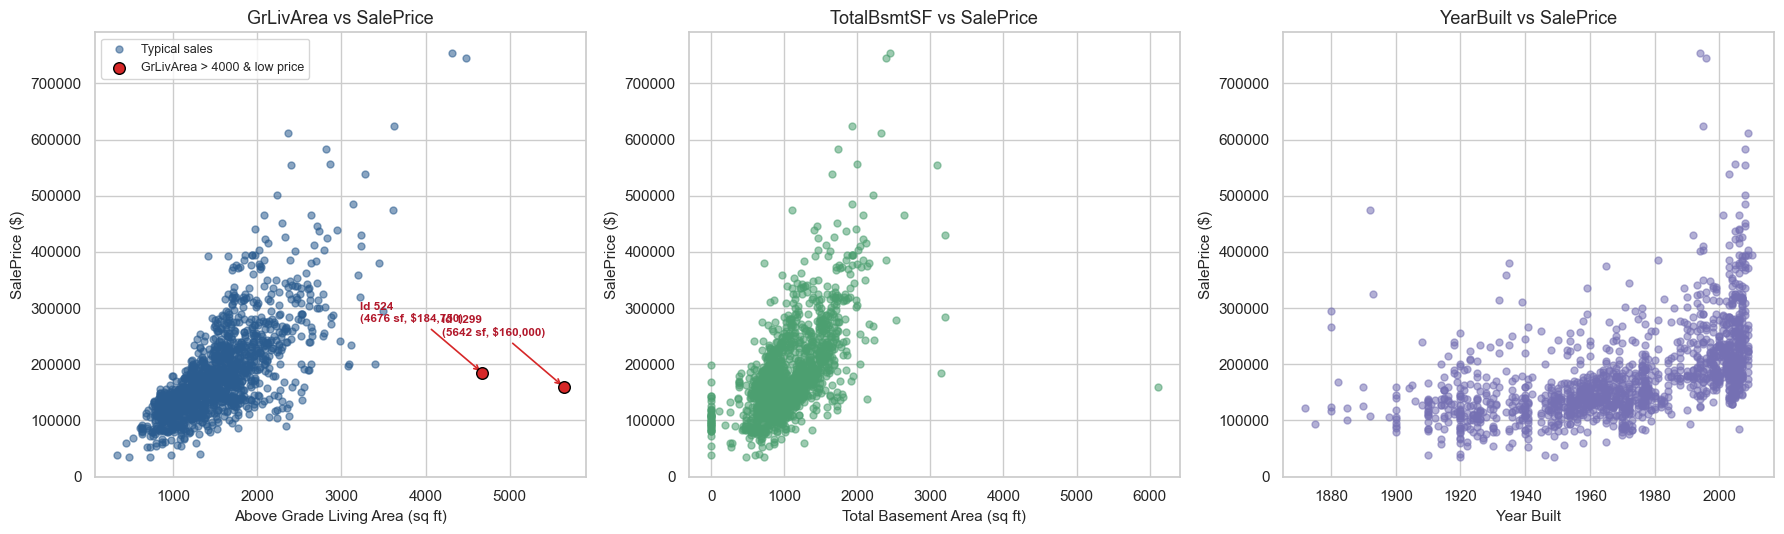

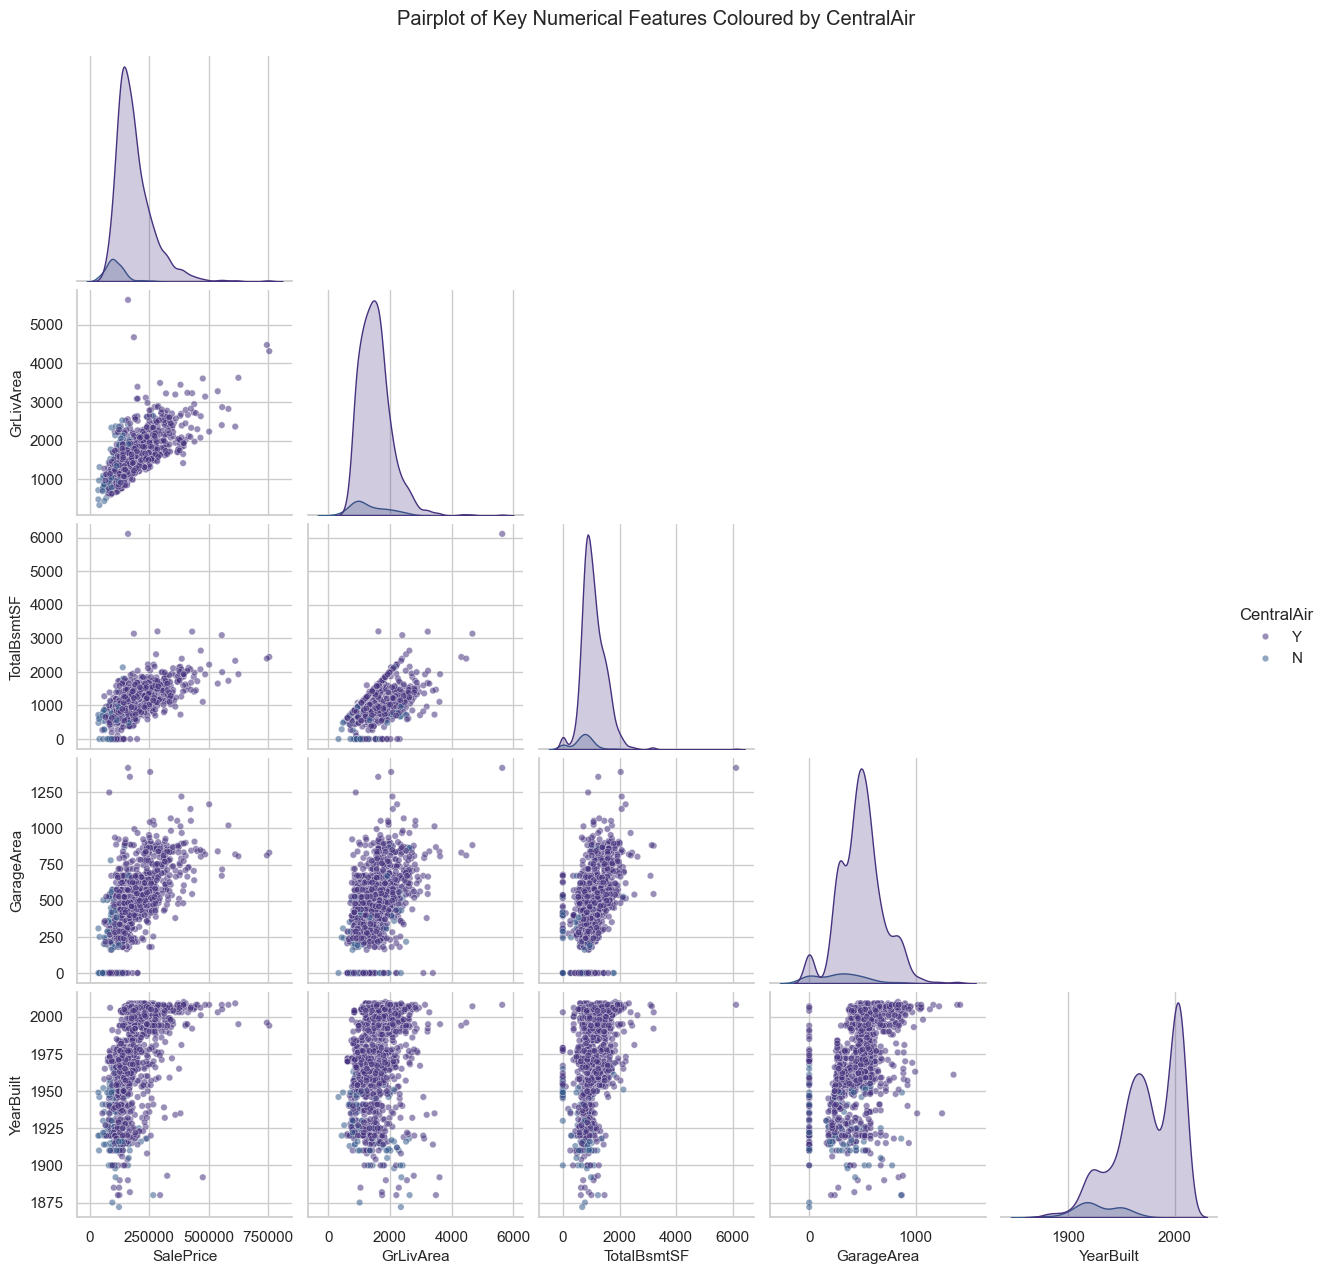

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Scatter 1: GrLivArea vs SalePrice with annotation on GrLivArea > 4000 & low price
low_price_giant = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
normal_pts = df.drop(low_price_giant.index)

axes[0].scatter(normal_pts["GrLivArea"], normal_pts["SalePrice"], alpha=0.55, s=25, color="#2b5c8f", label="Typical sales")
axes[0].scatter(low_price_giant["GrLivArea"], low_price_giant["SalePrice"], color="#d62728", s=70, edgecolor="black", zorder=5, label="GrLivArea > 4000 & low price")
for _, row in low_price_giant.iterrows():
    axes[0].annotate(
        f"Id {int(row['Id'])}\n({int(row['GrLivArea'])} sf, ${int(row['SalePrice']):,})",
        xy=(row["GrLivArea"], row["SalePrice"]),
        xytext=(row["GrLivArea"] - 1450, row["SalePrice"] + 90000),
        arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.2),
        fontsize=8.5, fontweight="bold", color="#b2182b"
    )
axes[0].set_title("GrLivArea vs SalePrice")
axes[0].set_xlabel("Above Grade Living Area (sq ft)")
axes[0].set_ylabel("SalePrice ($)")
axes[0].legend(loc="upper left", fontsize=9)

# Scatter 2: TotalBsmtSF vs SalePrice
axes[1].scatter(df["TotalBsmtSF"], df["SalePrice"], alpha=0.55, s=25, color="#4c9f70")
axes[1].set_title("TotalBsmtSF vs SalePrice")
axes[1].set_xlabel("Total Basement Area (sq ft)")
axes[1].set_ylabel("SalePrice ($)")

# Scatter 3: YearBuilt vs SalePrice
axes[2].scatter(df["YearBuilt"], df["SalePrice"], alpha=0.55, s=25, color="#7570b3")
axes[2].set_title("YearBuilt vs SalePrice")
axes[2].set_xlabel("Year Built")
axes[2].set_ylabel("SalePrice ($)")

plt.tight_layout()
plt.show()

selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "CentralAir"]
pair_grid = sns.pairplot(df[selected], hue="CentralAir", diag_kind="kde", corner=True, plot_kws={"alpha": 0.55, "s": 22})
pair_grid.fig.suptitle("Pairplot of Key Numerical Features Coloured by CentralAir", y=1.02)
plt.show()

### What We Learned (Step 6)
- **`GrLivArea` vs `SalePrice`**: Shows a clear positive linear trend, **except for two conspicuous outliers** in the lower-right (`Id=524`: 4,676 sq ft sold for \$184,750; `Id=1299`: 5,642 sq ft sold for \$160,000), both flagged as `Partial` sales in `Edwards`. Meanwhile, two ~4,300–4,500 sq ft homes in `NoRidge` sold for \$745k–\$755k right along the main upward trajectory.
- **`TotalBsmtSF` vs `SalePrice`**: Strong positive trend; notice the vertical band at `TotalBsmtSF = 0` (homes without basements) and one extreme ~6,110 sq ft basement (`Id=1299`, the same outlier).
- **`YearBuilt` vs `SalePrice`**: Newer homes (especially post-1990) command noticeably higher prices and higher ceilings, though well-maintained historic homes still fetch \$250k–\$450k.
- **Pairplot with `CentralAir`**: Homes without central air (`CentralAir = N`, 95 homes) cluster almost exclusively among older construction (`YearBuilt < 1975`) and lower prices.

### What We Are About to Do (Step 7: Correlation Heatmap)
We will construct a masked lower-triangle correlation heatmap of `SalePrice` and its top 10 correlated numeric features using a diverging `coolwarm` colormap centered at `0` with 2-decimal annotations.

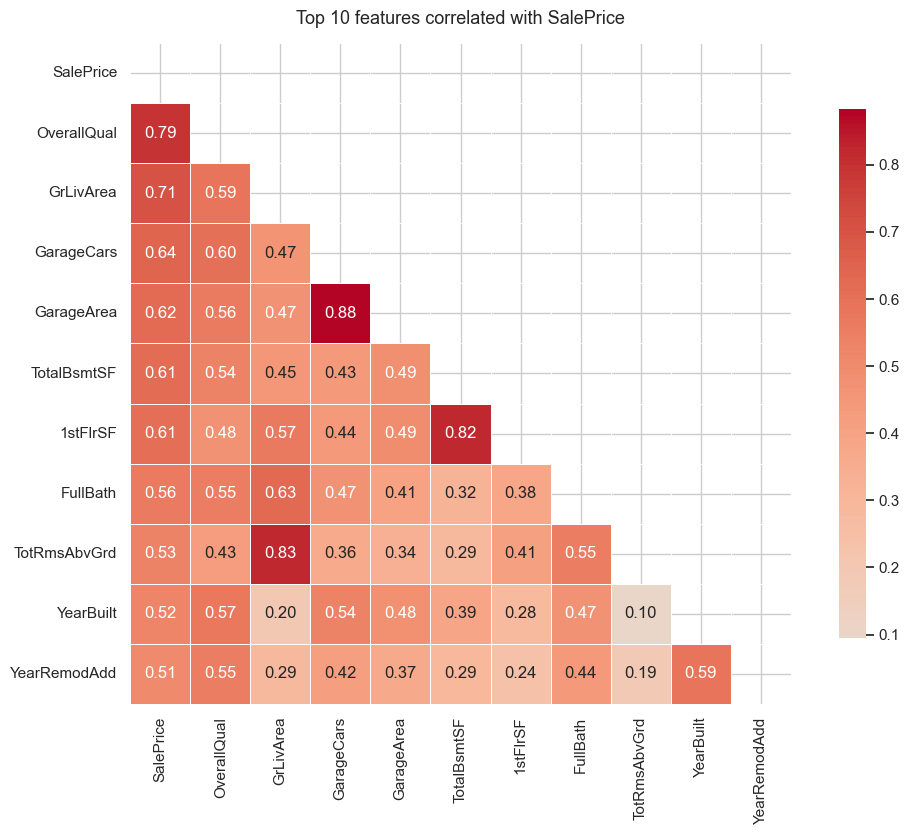

In [11]:
heatmap_cols = ["SalePrice"] + top10_features
corr_top = df[heatmap_cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Top 10 features correlated with SalePrice", pad=14)
plt.tight_layout()
plt.show()

### What We Learned (Step 7)
- The heatmap reveals tight **multicollinearity clusters** among predictors:
  - `GarageCars` & `GarageArea` (`r = 0.88`)
  - `GrLivArea` & `TotRmsAbvGrd` (`r = 0.83`)
  - `TotalBsmtSF` & `1stFlrSF` (`r = 0.82`)
  - `YearBuilt` & `YearRemodAdd` (`r = 0.59`) & `OverallQual` (`r = 0.57`)
- Notice how quality (`OverallQual`), living area (`GrLivArea`), and modern construction (`YearBuilt`) reinforce each other across the feature matrix.

## 7. Outlier Analysis (Step 8: IQR vs. Z-Score Comparison)

### What We Are About to Do
We will implement both `iqr_outliers` ($1.5 \times \text{IQR}$ rule) and `zscore_outliers` ($|z| > 3$), compare how many rows each flags for `GrLivArea` and `SalePrice` and their overlap, visualize the flagged points in boxplots and a `GrLivArea` vs `SalePrice` scatter plot, inspect the extreme `GrLivArea > 4000` records, and decide whether to create `df_clean`.

,Column,IQR Outliers,Z-Score (|z|>3) Outliers,Overlap
0,GrLivArea,31,16,16
1,SalePrice,61,22,22


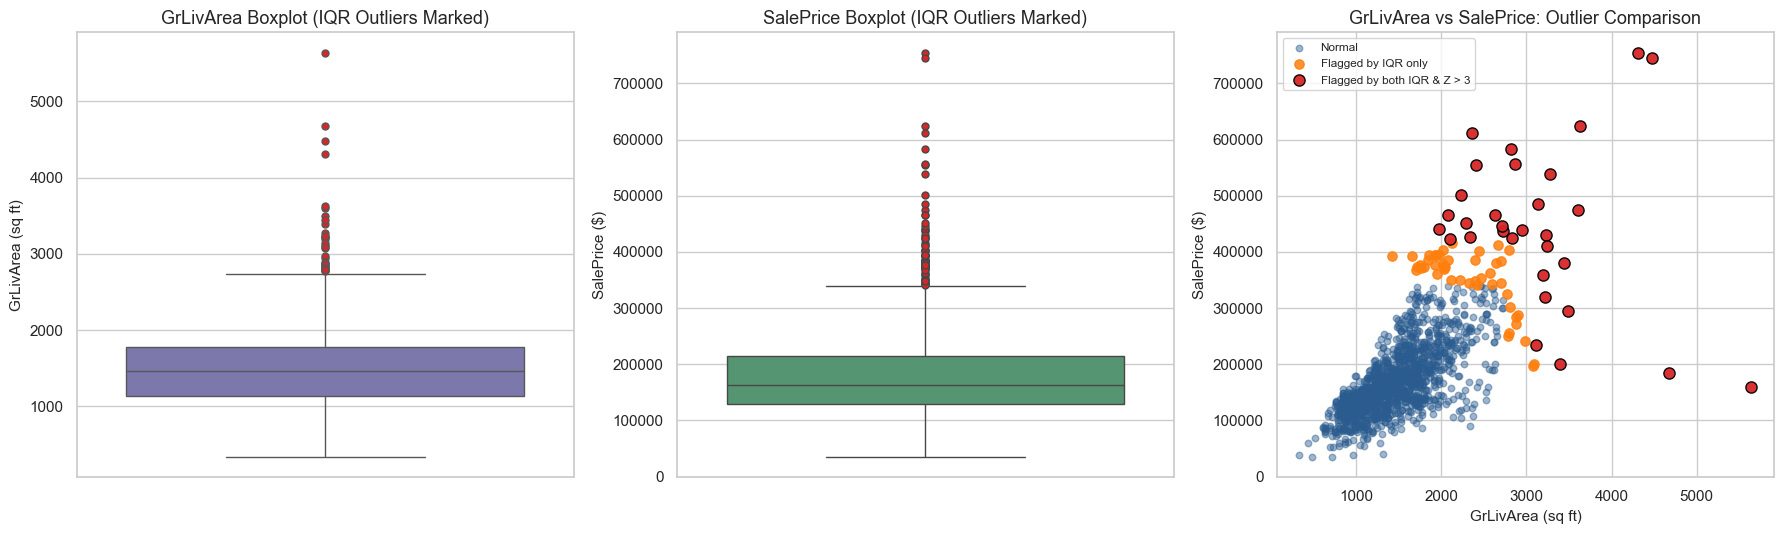


Inspecting all houses with GrLivArea > 4000:


,Id,Neighborhood,OverallQual,GrLivArea,TotalBsmtSF,SalePrice,SaleCondition
523,524,Edwards,10,4676,3138,184750,Partial
691,692,NoRidge,10,4316,2444,755000,Normal
1182,1183,NoRidge,10,4476,2396,745000,Abnorml
1298,1299,Edwards,10,5642,6110,160000,Partial


Original rows: 1460 | Removed unusual partial sales: 2 | df_clean rows: 1458
Pearson r(GrLivArea, SalePrice) before: 0.7086
Pearson r(GrLivArea, SalePrice) in df_clean: 0.7350


In [12]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

outlier_summary = []
flagged = {}
for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col], threshold=3)
    overlap = a.index.intersection(b.index)
    flagged[col] = {"iqr": a.index, "z": b.index, "overlap": overlap}
    outlier_summary.append({
        "Column": col,
        "IQR Outliers": len(a),
        "Z-Score (|z|>3) Outliers": len(b),
        "Overlap": len(overlap)
    })

display(pd.DataFrame(outlier_summary))

# Visualize boxplots and GrLivArea vs SalePrice with flagged points
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

sns.boxplot(y=df["GrLivArea"], color="#7570b3", ax=axes[0], flierprops=dict(marker="o", markerfacecolor="#d62728", markersize=5))
axes[0].set_title("GrLivArea Boxplot (IQR Outliers Marked)")
axes[0].set_ylabel("GrLivArea (sq ft)")

sns.boxplot(y=df["SalePrice"], color="#4c9f70", ax=axes[1], flierprops=dict(marker="o", markerfacecolor="#d62728", markersize=5))
axes[1].set_title("SalePrice Boxplot (IQR Outliers Marked)")
axes[1].set_ylabel("SalePrice ($)")

iqr_any = flagged["GrLivArea"]["iqr"].union(flagged["SalePrice"]["iqr"])
z_any = flagged["GrLivArea"]["z"].union(flagged["SalePrice"]["z"])
iqr_only = iqr_any.difference(z_any)
normal_mask = ~df.index.isin(iqr_any.union(z_any))

axes[2].scatter(df.loc[normal_mask, "GrLivArea"], df.loc[normal_mask, "SalePrice"], alpha=0.45, s=22, color="#2b5c8f", label="Normal")
axes[2].scatter(df.loc[iqr_only, "GrLivArea"], df.loc[iqr_only, "SalePrice"], alpha=0.85, s=45, color="#ff7f0e", label="Flagged by IQR only")
axes[2].scatter(df.loc[z_any, "GrLivArea"], df.loc[z_any, "SalePrice"], alpha=0.95, s=65, color="#d62728", edgecolor="black", label="Flagged by both IQR & Z > 3")
axes[2].set_title("GrLivArea vs SalePrice: Outlier Comparison")
axes[2].set_xlabel("GrLivArea (sq ft)")
axes[2].set_ylabel("SalePrice ($)")
axes[2].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

print("\nInspecting all houses with GrLivArea > 4000:")
display(df[df["GrLivArea"] > 4000][["Id", "Neighborhood", "OverallQual", "GrLivArea", "TotalBsmtSF", "SalePrice", "SaleCondition"]])

# Decision: remove the 2 non-typical giant-area / low-price partial sales; keep genuine luxury sales
unusual_idx = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index
df_clean = df.drop(index=unusual_idx).copy()

print(f"Original rows: {len(df)} | Removed unusual partial sales: {len(unusual_idx)} | df_clean rows: {len(df_clean)}")
print(f"Pearson r(GrLivArea, SalePrice) before: {df['GrLivArea'].corr(df['SalePrice']):.4f}")
print(f"Pearson r(GrLivArea, SalePrice) in df_clean: {df_clean['GrLivArea'].corr(df_clean['SalePrice']):.4f}")

### What We Learned (Step 8) & Interpretation Prompt
- **IQR vs. Z-Score Counts**:
  - `GrLivArea`: IQR flags **31** points, Z-score (`|z| > 3`) flags **16** points (100% of Z-score outliers are a subset of IQR outliers: overlap = **16**).
  - `SalePrice`: IQR flags **61** points, Z-score (`|z| > 3`) flags **22** points (overlap = **22**).
- **Outlier Decision (`df_clean`)**:
  - Among the 4 homes with `GrLivArea > 4,000`, `Id=692` (\$755,000) and `Id=1183` (\$745,000) are genuine luxury `NoRidge` mansions that align with the size-price trend, so we **keep** them.
  - Conversely, `Id=524` (4,676 sq ft, \$184,750) and `Id=1299` (5,642 sq ft, \$160,000) are both `Partial` sales in `Edwards` with `OverallQual = 10` (`Id=524` also had `YearRemodAdd > YrSold`). These two non-typical sales severely distort linear relationships: removing just these **2 rows** to form `df_clean` (1,458 rows) increases the `GrLivArea`–`SalePrice` Pearson correlation from **0.7086** to **0.7350**.
- **Interpretation Prompt — Why does the z-score method flag fewer points on a skewed variable than the IQR method?**
  - In a right-skewed distribution, extreme values in the long upper tail pull the **sample mean** upward and dramatically inflate the **standard deviation** (which squares deviations from the mean). As a result, the `mean + 3 * std` cutoff shifts far out into the tail. By contrast, the IQR method relies on the **25th and 75th percentiles**, which are resistant to extreme tail values, yielding a tighter upper fence (`Q3 + 1.5 * IQR`) that flags more upper-tail points.

## 8. Final Dashboard and Storytelling (Step 10)

### What We Are About to Do
We will synthesize our key findings into a single clean 2×2 executive summary figure (`figsize=(14, 10)`) titled **"House Price EDA Summary"** using a consistent color palette and tight layout, and export it to `eda_dashboard.png`:
- **Panel 1 (Matplotlib line plot)**: Mean `SalePrice` by `YearBuilt`
- **Panel 2 (Matplotlib horizontal bar plot)**: Top 10 `Neighborhood`s by mean `SalePrice`
- **Panel 3 (Seaborn histplot with KDE)**: `SalePrice` distribution with vertical dashed lines for Mean and Median
- **Panel 4 (Seaborn scatter plot)**: `GrLivArea` vs `SalePrice` coloured by `OverallQual`

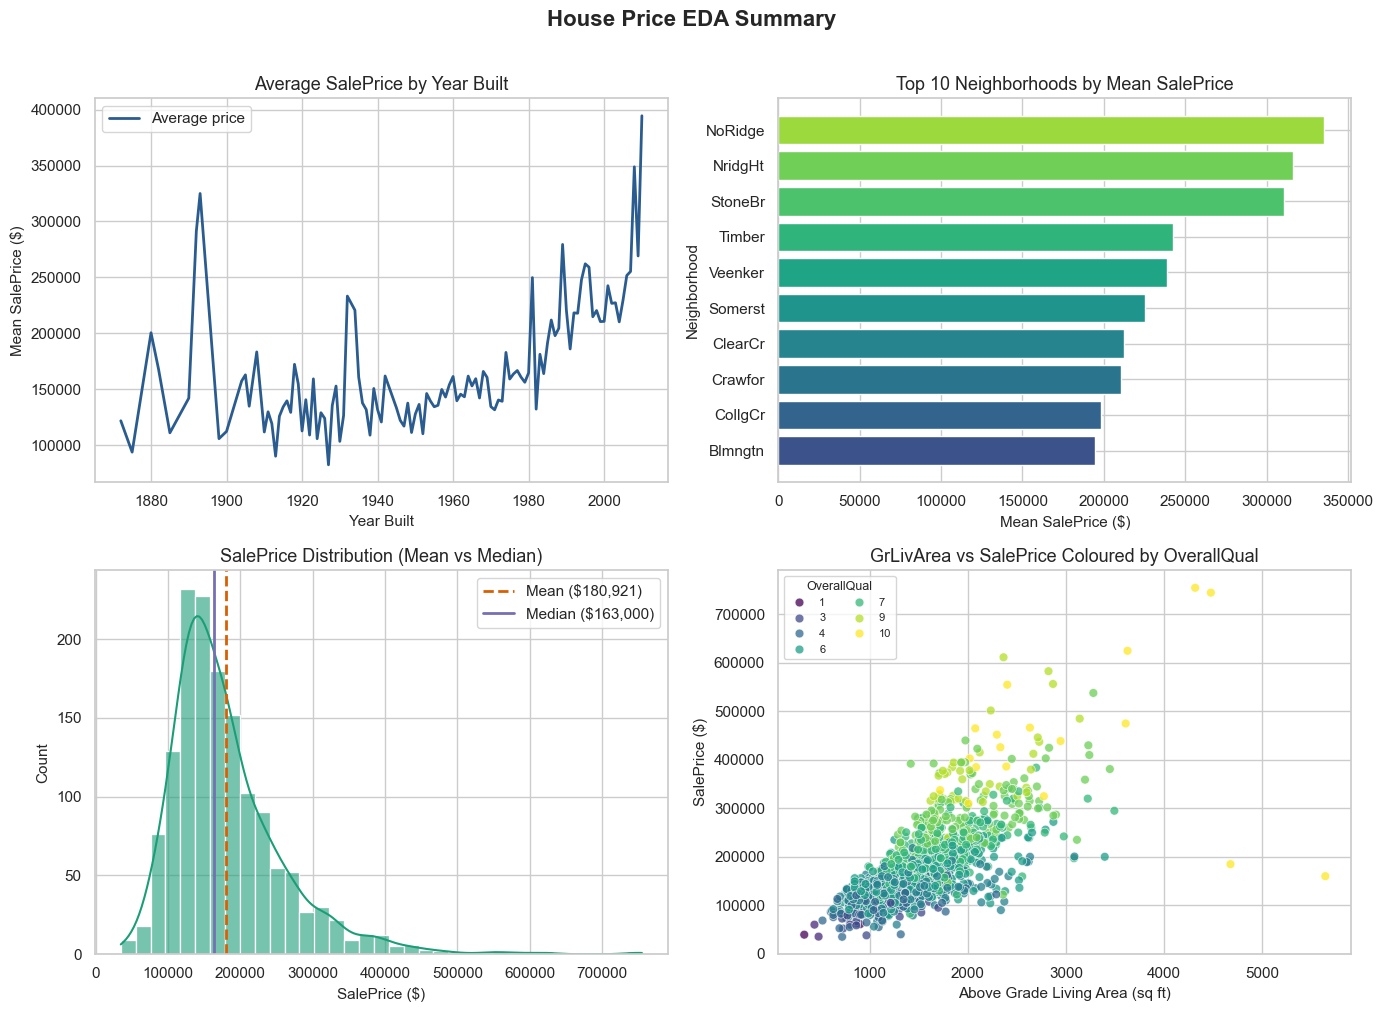

Saved dashboard to eda_dashboard.png


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette_main = "#2b5c8f"
palette_accent = "#d95f02"
palette_teal = "#1b9e77"

# Panel 1: Matplotlib line plot — mean SalePrice by YearBuilt
yearly_price = df.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(yearly_price.index, yearly_price.values, color=palette_main, linewidth=2, label="Average price")
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Mean SalePrice ($)")
axes[0, 0].legend(loc="upper left")

# Panel 2: Matplotlib horizontal bar plot — Top 10 Neighborhoods by mean SalePrice
top10_neigh = df.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=True).tail(10)
bar_colors = plt.cm.viridis(np.linspace(0.25, 0.85, len(top10_neigh)))
axes[0, 1].barh(top10_neigh.index, top10_neigh.values, color=bar_colors)
axes[0, 1].set_title("Top 10 Neighborhoods by Mean SalePrice")
axes[0, 1].set_xlabel("Mean SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: Seaborn histplot with KDE + mean & median vertical lines
mean_p = df["SalePrice"].mean()
median_p = df["SalePrice"].median()
sns.histplot(df["SalePrice"], kde=True, bins=35, color=palette_teal, alpha=0.6, ax=axes[1, 0])
axes[1, 0].axvline(mean_p, color=palette_accent, linestyle="--", linewidth=2, label=f"Mean (${mean_p:,.0f})")
axes[1, 0].axvline(median_p, color="#7570b3", linestyle="-", linewidth=2, label=f"Median (${median_p:,.0f})")
axes[1, 0].set_title("SalePrice Distribution (Mean vs Median)")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4: Seaborn scatter — GrLivArea vs SalePrice coloured by OverallQual
sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75,
    s=40,
    ax=axes[1, 1]
)
axes[1, 1].set_title("GrLivArea vs SalePrice Coloured by OverallQual")
axes[1, 1].set_xlabel("Above Grade Living Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")
axes[1, 1].legend(title="OverallQual", ncol=2, fontsize=8, title_fontsize=9, loc="upper left")

fig.suptitle("House Price EDA Summary", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig("eda_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved dashboard to eda_dashboard.png")

### What We Learned
- The 4-panel dashboard visually unifies our core EDA story: newer construction (`YearBuilt` post-1990) commands sharply higher average prices, top neighborhoods (`NoRidge`, `NridgHt`, `StoneBr`) average above **\$310k**, `SalePrice` exhibits a clear right-skewed distribution where the mean exceeds the median by **\$17,921**, and `GrLivArea` + `OverallQual` jointly stratify the market—except for the two unusual low-price `Partial` sales above 4,500 sq ft.

## 9. Conclusions: Insights and Limitations

### Answers to Our Six Guiding Questions
1. **How is `SalePrice` distributed? Is it skewed?**
   - `SalePrice` ranges from **\$34,900** to **\$755,000** with a median of **\$163,000** and a mean of **\$180,921.20**. It is strongly **right-skewed** (skewness = **1.8829**); applying `log1p` lowers skewness to **0.1213**, making it nearly normal.
2. **Which numerical features correlate most strongly with `SalePrice`?**
   - `OverallQual` (`r = 0.7910`), `GrLivArea` (`r = 0.7086`; **0.7350** after removing the 2 partial-sale outliers), `GarageCars` (`r = 0.6404`), `GarageArea` (`r = 0.6234`), `TotalBsmtSF` (`r = 0.6136`), and `1stFlrSF` (`r = 0.6059`).
3. **Does overall quality (`OverallQual`) change price in a clear, ordered way?**
   - **Yes.** Median `SalePrice` increases monotonically at every rating from 1 (**\$50,150**) through 5 (**\$133,000**) up to 10 (**\$432,390**), with wider price dispersion at higher quality tiers (Spearman $\rho = 0.8098$).
4. **Do some neighborhoods consistently cost more than others?**
   - **Yes.** `NridgHt` (median **\$315,000**, mean **\$316,271**), `NoRidge` (median **\$301,500**, mean **\$335,295**), and `StoneBr` (median **\$278,000**, mean **\$310,499**) cost roughly 3× more than `MeadowV` (median **\$88,000**) and `IDOTRR` (median **\$103,000**).
5. **Are there outliers, and are they errors or real but unusual sales?**
   - IQR flags 31 outliers in `GrLivArea` and 61 in `SalePrice` (vs. 16 and 22 via $|z| > 3$). Most high-price points (e.g., `Id=692` at \$755,000 and `Id=1183` at \$745,000 in `NoRidge`) are genuine luxury homes along the trend. However, two properties (`Id=524`: 4,676 sq ft for \$184,750; `Id=1299`: 5,642 sq ft for \$160,000) are unusual `Partial` sales in `Edwards` that distort linear trend lines and warrant separation (`df_clean`).
6. **Which columns have missing values, and which of those are not truly missing?**
   - **19 columns** have missing values, but **15** of them primarily encode *"feature absent"* (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, and `MasVnrType`). Only `LotFrontage` (259), `Electrical` (1), `BsmtExposure` (`Id=949`), `BsmtFinType2` (`Id=333`), and 8 `MasVnrArea` entries represent genuinely missing values.

### Verification of Expected Insights (Section 7 Checklist)
- **Verified**: `SalePrice` is right-skewed (`1.8829`), and a log transform makes it close to normal (`0.1213`).
- **Verified**: `OverallQual` (`0.7910`) and `GrLivArea` (`0.7086`) are the two strongest correlates of `SalePrice`.
- **Verified**: Price rises steadily across `OverallQual` tiers, with the largest spread at tiers 9–10 (`std` \$81k–\$160k).
- **Verified**: `NridgHt`, `NoRidge`, and `StoneBr` have markedly higher medians than the rest of Ames.
- **Verified**: Two very large `Partial` sales (`Id=524`, `Id=1299`) with low prices distort the `GrLivArea`–`SalePrice` trend line.
- **Verified**: Apparent missing values in amenities, garages, and basements largely mean *"feature absent"* and should be encoded as `"None"` rather than dropped.

### Limitations
- **Geographic & Temporal Scope**: Data reflect residential sales in **Ames, Iowa (2006–2010)** and may not generalize directly to other cities or current market cycles.
- **Observational / Univariate Correlations**: Pairwise correlations do not establish causation; strong predictors (`OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`) are heavily collinear.
- **EDA Scope**: Per the project objective, no predictive regression models or formal causal tests were fit here.